<a href="https://colab.research.google.com/github/ikabrain/UCS772-CV-NLP-Lab/blob/main/NLP_CV_assign7/CV_assign7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 7 - Face Detection
---

In [1]:
# Update to latest opencv with legacy methods included in contrib
!pip uninstall -q -y opencv-python opencv-python-headless opencv-contrib-python
!pip install -q opencv-contrib-python

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Import the Google Colab specific image display tool
from google.colab.patches import cv2_imshow

## Q1: Detect faces from live images taken from webcam
---

We'll be using the traditional [Haar feature-based cascade classifiers trained with Haar-like features using the Viola-Jones algorithm](https://www.face-rec.org/algorithms/Boosting-Ensemble/16981346.pdf).

Tutorial for same is [here](https://docs.opencv.org/5.0/tutorials_contrib/xobjdetect/cascade_classifier/cascade_classifier.html).

In [2]:
# Install and initialize the Haar Cascade face detection model
!wget -qnc -O haarcascade_frontalface_default.xml https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_frontalface_default.xml

try:
    face_cascade = cv2.CascadeClassifier('haarcascade_frontalface_default.xml')
    if face_cascade.empty():
        raise FileNotFoundError
except:
    raise FileNotFoundError("Could not load the Haar Cascade face detection model.")

In [3]:
# scaleFactor: Dictates image reduction ratio at subsequent pyramid layers (1.1 = 10% reduction)
# minNeighbors: Dictates structural validation density (higher values reduce false positives)
# minSize: Minimum possible object size. Objects smaller than this are ignored.
SCALE_FACTOR, MIN_NEIGHBORS, MIN_SIZE = 1.1, 5, (30, 30)

### Capturing webcam image

In [4]:
# @markdown Run this cell to init JS to take photo in Colab using `take_photo` {"vertical-output":true,"form-width":"50%","single-column":true,"display-mode":"form"}
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def take_photo(filename='photo.jpg', quality=0.8):
    js = Javascript('''
        async function takePhoto(quality) {
        const div = document.createElement('div');
        const capture = document.createElement('button');
        capture.textContent = 'Capture';
        div.appendChild(capture);

        const video = document.createElement('video');
        video.style.display = 'block';
        const stream = await navigator.mediaDevices.getUserMedia({video: true});

        document.body.appendChild(div);
        div.appendChild(video);
        video.srcObject = stream;
        await video.play();

        // Resize the output to fit the video element.
        google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

        // Wait for Capture to be clicked.
        await new Promise((resolve) => capture.onclick = resolve);

        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;
        canvas.getContext('2d').drawImage(video, 0, 0);
        stream.getVideoTracks()[0].stop();
        div.remove();
        return canvas.toDataURL('image/jpeg', quality);
        }
        ''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    binary = b64decode(data.split(',')[1])
    with open(filename, 'wb') as f:
        f.write(binary)
    return filename

<IPython.core.display.Javascript object>

Saved to photo.jpg


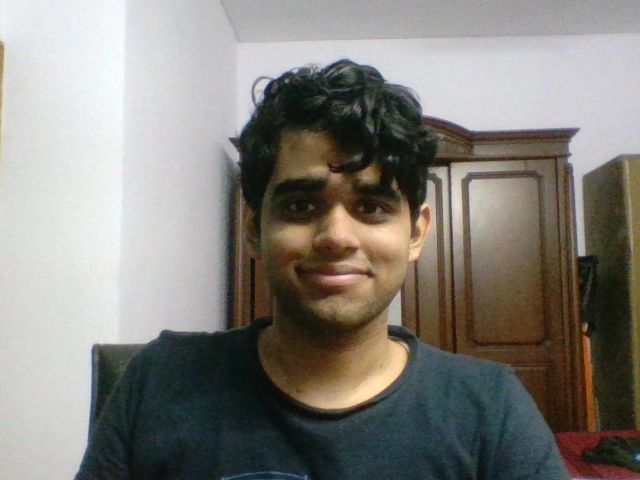

In [5]:
# Capturing photo (saved to `filename`)
from IPython.display import Image

try:
    filename = take_photo("photo.jpg")
    print('Saved to {}'.format(filename))
    display(Image(filename)) # shows the image which was just taken
except Exception as err:
    # Errors will be thrown if the user does not have a webcam or if they do not grant the page permission to access it
    print(str(err))

### Preprocessing the image

In [6]:
# Read and convert the image to grayscale
img = cv2.imread("photo.jpg")
if img is None:
    raise FileNotFoundError("Could not load the target image.")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

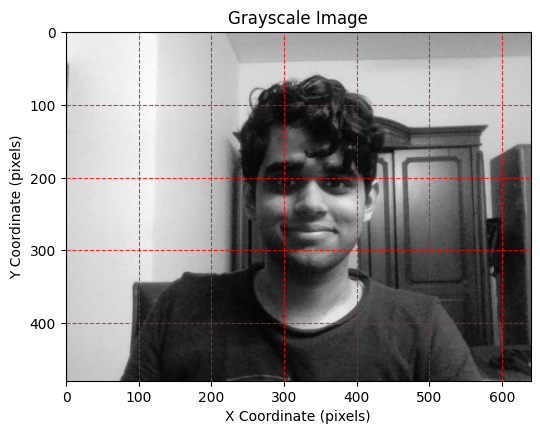

In [7]:
# Plot the image using matplotlib with axes, gridlines, and custom figure size
plt.figure(figsize=(6, 6))
plt.imshow(gray, cmap='gray')
plt.grid(True, color='red', alpha=0.8, linestyle='--')
plt.title("Grayscale Image")
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

### Detecting faces

In [8]:
# Execute Multi-scale Face Detection
def detect_faces(frame):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    return face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))

faces = detect_faces(img)

In [9]:
# Enumerate coordinates and generate bound visualization overlays
def draw_boxes(img, boxes, thickness=2):
    """Draw blue rectangles on img in place; works for BGR (3 channels) and BGRA (4 channels)."""
    color = (255, 0, 0, 255)[:img.shape[2]]
    for (x, y, w, h) in boxes:
        cv2.rectangle(img, (x, y), (x + w, y + h), color, thickness)
    return img

img = draw_boxes(img, faces)

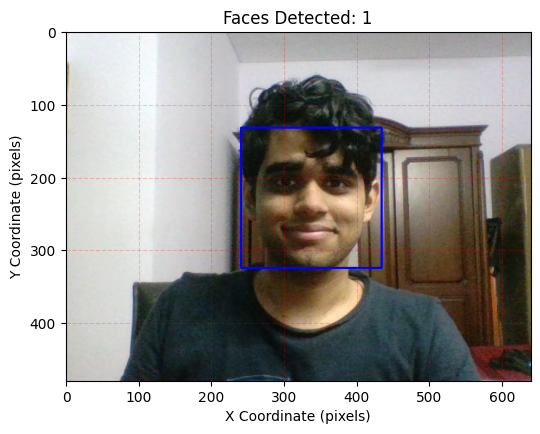

In [10]:
# Display the resulting visualized layer
plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.grid(True, color='red', alpha=0.2, linestyle='--')
plt.title(f"Faces Detected: {len(faces)}")
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

### Q2: Once you're done with images, then take short live video sequence and detect faces
---

### Showing live webcam feed in Colab

In [11]:
# @markdown Run this cell to init JS to open webcam video feed in Colab using `video_stream` and serve frames to `video_frames(label, next_frame_as_jpeg_data_url)` {"vertical-output":true,"form-width":"50%","single-column":true,"display-mode":"form"}
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def video_stream():
    """Inject the JS that opens the webcam once and serves frames on request."""
    js = Javascript('''
    var video;
    var div = null;
    var stream;
    var captureCanvas;
    var imgElement;
    var labelElement;

    var pendingResolve = null;
    var shutdown = false;

    function removeDom() {
      stream.getVideoTracks()[0].stop();
      video.remove();
      div.remove();
      video = null;
      div = null;
      stream = null;
      imgElement = null;
      captureCanvas = null;
      labelElement = null;
    }

    function onAnimationFrame() {
      if (!shutdown) {
        window.requestAnimationFrame(onAnimationFrame);
      }
      if (pendingResolve) {
        var result = "";
        if (!shutdown) {
          captureCanvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
          result = captureCanvas.toDataURL('image/jpeg', 0.8);
        }
        var resolveNow = pendingResolve;
        pendingResolve = null;
        resolveNow(result);
      }
    }

    async function createDom() {
      if (div !== null) {
        return stream;
      }

      div = document.createElement('div');
      div.style.border = '2px solid black';
      div.style.padding = '3px';
      div.style.width = '100%';
      div.style.maxWidth = '600px';
      document.body.appendChild(div);

      const statusRow = document.createElement('div');
      statusRow.innerHTML = '<span>Status: </span>';
      labelElement = document.createElement('span');
      labelElement.innerText = 'No data';
      labelElement.style.fontWeight = 'bold';
      statusRow.appendChild(labelElement);
      div.appendChild(statusRow);

      video = document.createElement('video');
      video.style.display = 'block';
      video.width = div.clientWidth - 6;
      video.setAttribute('playsinline', '');
      video.onclick = () => { shutdown = true; };
      stream = await navigator.mediaDevices.getUserMedia({video: {facingMode: 'user'}});
      div.appendChild(video);

      imgElement = document.createElement('img');
      imgElement.style.position = 'absolute';
      imgElement.style.zIndex = 1;
      imgElement.onclick = () => { shutdown = true; };
      div.appendChild(imgElement);

      const instruction = document.createElement('div');
      instruction.innerHTML =
          '<span style="color: red; font-weight: bold;">' +
          'When finished, click here or on the video to stop</span>';
      div.appendChild(instruction);
      instruction.onclick = () => { shutdown = true; };

      video.srcObject = stream;
      await video.play();

      captureCanvas = document.createElement('canvas');
      captureCanvas.width = 640;
      captureCanvas.height = 480;
      window.requestAnimationFrame(onAnimationFrame);

      return stream;
    }

    async function stream_frame(label, imgData) {
      if (shutdown) {
        removeDom();
        shutdown = false;
        return '';
      }

      stream = await createDom();

      if (label !== "") {
        labelElement.innerHTML = label;
      }

      if (imgData != "") {
        var videoRect = video.getClientRects()[0];
        imgElement.style.top = videoRect.top + "px";
        imgElement.style.left = videoRect.left + "px";
        imgElement.style.width = videoRect.width + "px";
        imgElement.style.height = videoRect.height + "px";
        imgElement.src = imgData;
      }

      var result = await new Promise(function(resolve, reject) {
        pendingResolve = resolve;
      });

      // The user may have clicked while we were waiting for the frame.
      if (shutdown) {
        removeDom();
        shutdown = false;
        return '';
      }
      return result;
    }
    ''')
    display(js)

def video_frame(label, overlay_url):
    """Ask the browser for the next frame (as a JPEG data URL) and give it the last overlay to show."""
    return eval_js('stream_frame("{}", "{}")'.format(label, overlay_url))

In [12]:
# Defining function to stream webcam video
import time
from base64 import b64encode

def stream_webcam(process=None, snapshot_every=3, max_snapshots=1):
    """
    Show the live webcam feed in this cell until you click it.

    process: optional function(frame) -> list of (x, y, w, h) boxes, where frame is a BGR array.
             With process=None you just get the raw live feed.

    Returns a few snapshots (BGR arrays), since the widget disappears when you stop.
    """
    video_stream()
    label, overlay_url = 'Starting...', ''
    snapshots, n, t0 = [], 0, time.time()

    while data_url := video_frame(label, overlay_url):    # '' (falsy) means user clicked stop
        jpeg_bytes = b64decode(data_url.split(',')[1])
        frame = cv2.imdecode(np.frombuffer(jpeg_bytes, dtype=np.uint8), cv2.IMREAD_COLOR)

        boxes = process(frame) if process else []
        if process:  # always send an overlay, even an empty one, so old boxes get cleared!
            overlay = draw_boxes(np.zeros((*frame.shape[:2], 4), dtype=np.uint8), boxes)
            ok, png = cv2.imencode('.png', overlay)
            overlay_url = 'data:image/png;base64,' + b64encode(png.tobytes()).decode('utf-8')

        n += 1
        label = f'{n / (time.time() - t0):.1f} fps' + (f' | detections: {len(boxes)}' if process else '')
        if (not process or len(boxes)) and n % snapshot_every == 0 and len(snapshots) < max_snapshots:
            snapshots.append(draw_boxes(frame.copy(), boxes))

    return snapshots

<IPython.core.display.Javascript object>

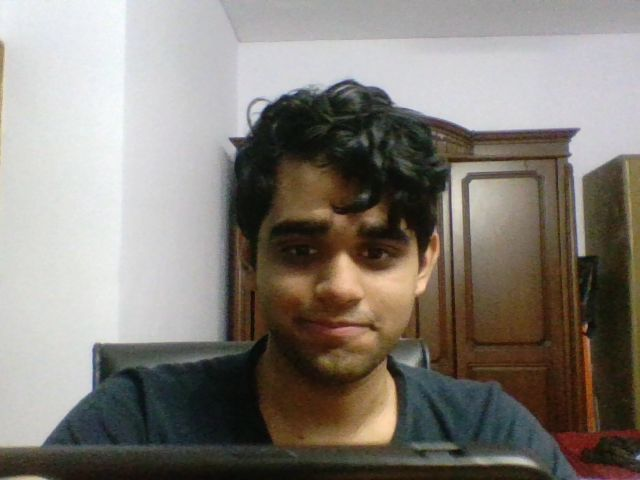

In [13]:
# Running webcam video in Colab
snapshots = stream_webcam()
for s in snapshots:
    cv2_imshow(s)   # Live widget disappears when we stop so we show the saved snapshots in the output

### Detecting faces live

<IPython.core.display.Javascript object>

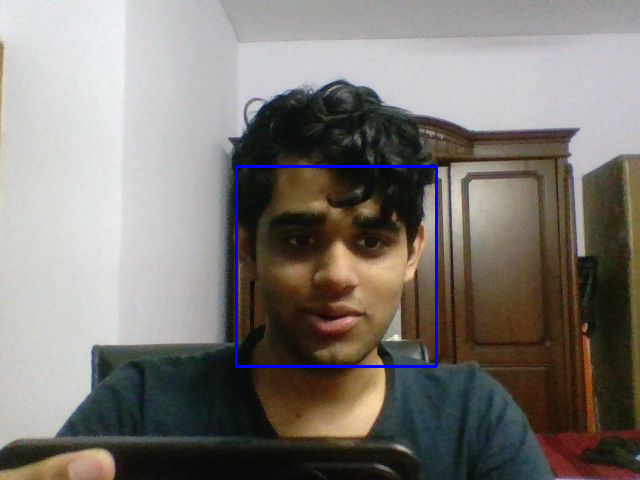

In [14]:
snapshots = stream_webcam(detect_faces)
for s in snapshots:
    cv2_imshow(s)

## Q3: Detect faces in mask wearing images
---